# Task 5 (Level 3 — Advanced): Random Forest Classifier, Feature Importance & Stability

Evaluates bagged tree ensembles on Customer Churn, contrasting Impurity-Based Feature Importance (MDI) against 30-repeat Permutation Importance and assessing stability across 10 independent random seeds.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
m5 = json.loads((ROOT / 'results/metrics/task5_random_forest_metrics.json').read_text())
imp_df = pd.read_csv(ROOT / 'results/tables/task5_rf_feature_importance_comparison.csv')
stab_df = pd.read_csv(ROOT / 'results/tables/task5_rf_seed_stability.csv')
print('Selected RF Hyperparameters:', m5['best_hyperparameters'])
ev = m5['tuned_rf_test_oof_optimal']
print(f"Held-Out Test: Acc={ev['accuracy']:.4f} | Prec={ev['precision']:.4f} | Rec={ev['recall']:.4f} | F1={ev['f1']:.4f} | ROC-AUC={ev['roc_auc']:.4f} | PR-AUC={ev['pr_auc']:.4f}")
print('10-Seed Stability Summary:', m5['stability_10_seeds'])
print('High-Cardinality Bias Demo (State 51 dummies):', m5['state_high_cardinality_bias_demo'])
print('Collinearity MDI Dilution Demo:', m5['collinearity_mdi_dilution_demo'])
display(imp_df.sort_values('perm_importance_mean', ascending=False))

Selected RF Hyperparameters: {'n_estimators': 300, 'max_depth': 16, 'min_samples_leaf': 2, 'max_features': 0.4, 'class_weight': None, 'cv_pr_auc_mean': 0.863751, 'oof_selected_threshold': 0.44, 'oof_f1_at_selected_threshold': 0.830084}
Held-Out Test: Acc=0.9565 | Prec=0.9024 | Rec=0.7789 | F1=0.8362 | ROC-AUC=0.9258 | PR-AUC=0.8828
10-Seed Stability Summary: {'roc_auc_mean': 0.926844, 'roc_auc_std': 0.002142, 'pr_auc_mean': 0.884324, 'pr_auc_std': 0.001694, 'f1_mean': 0.850713, 'f1_std': 0.006402}
High-Cardinality Bias Demo (State 51 dummies): {'state_mdi_sum_51_dummies': 0.040153, 'state_permutation_auc_drop': 0.000242}
Collinearity MDI Dilution Demo: {'pruned_total_day_minutes_mdi': 0.260374, 'unpruned_total_day_minutes_mdi': 0.134918, 'unpruned_total_day_charge_mdi': 0.129661}


,feature,n_encoded_columns,mdi_importance,mdi_std,perm_importance_mean,perm_importance_std
0,Total day minutes,1,0.260374,0.042159,0.211788,0.020429
1,Customer service calls,1,0.128485,0.022307,0.133915,0.013026
3,International plan,1,0.105176,0.041264,0.074793,0.007088
2,Total eve minutes,1,0.106354,0.026814,0.041875,0.008175
4,Total intl minutes,1,0.079399,0.027972,0.025471,0.005079
5,Total intl calls,1,0.070623,0.030292,0.022566,0.006276
10,Number vmail messages,1,0.027414,0.018110,0.009067,0.003032
13,Voice mail plan,1,0.019186,0.018335,0.003908,0.001152
6,Total night minutes,1,0.044777,0.016149,0.003708,0.002593
14,Area code,3,0.010395,0.007213,0.001151,0.000775


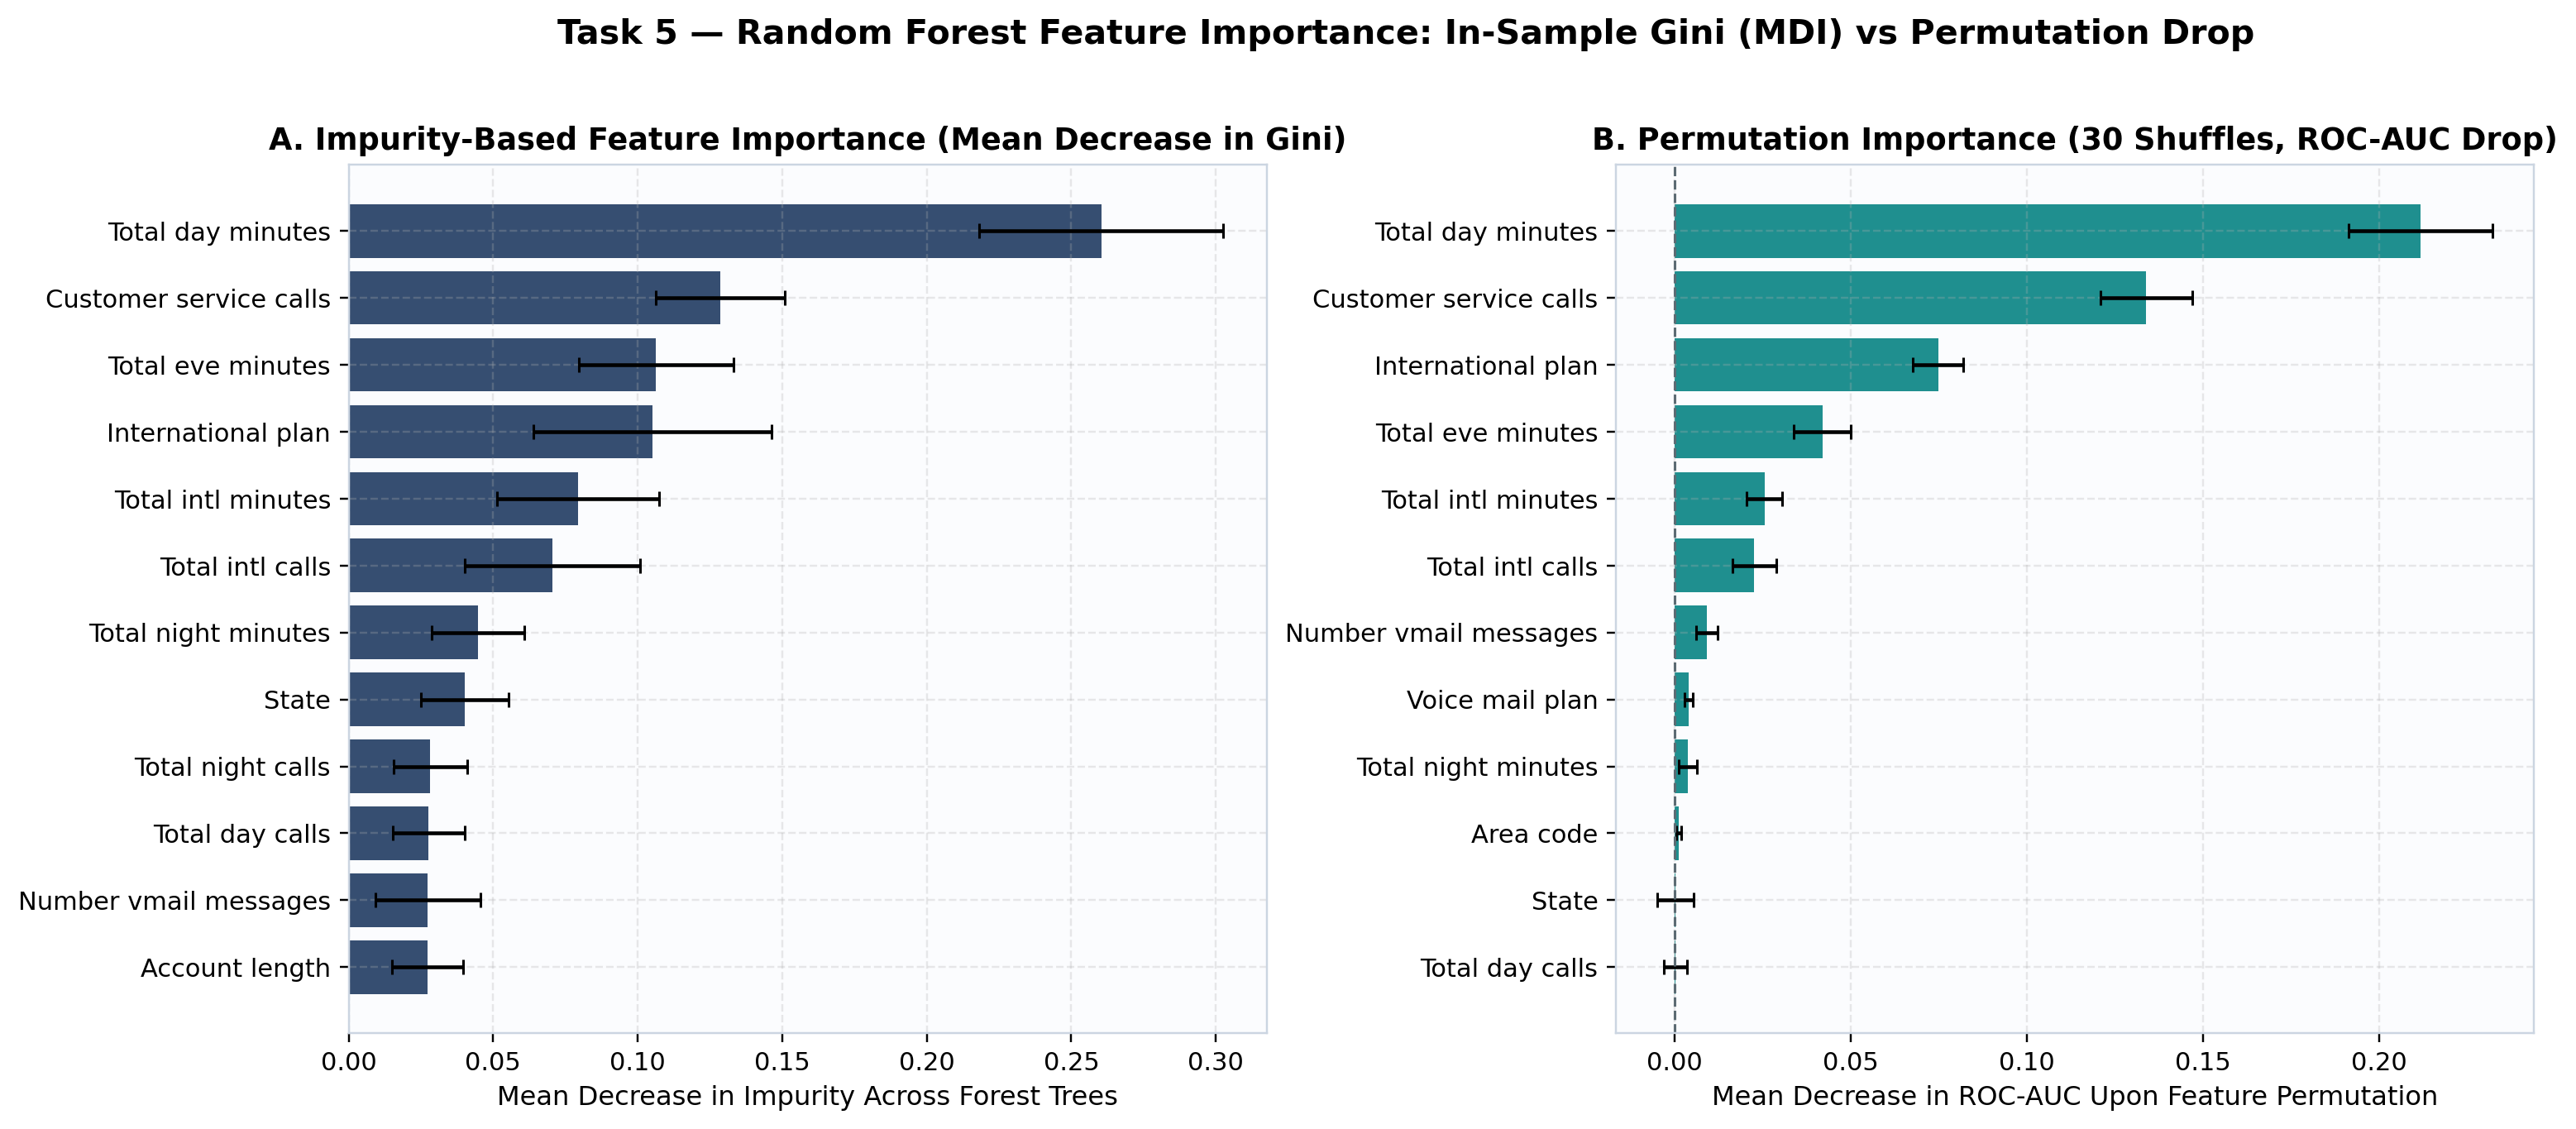

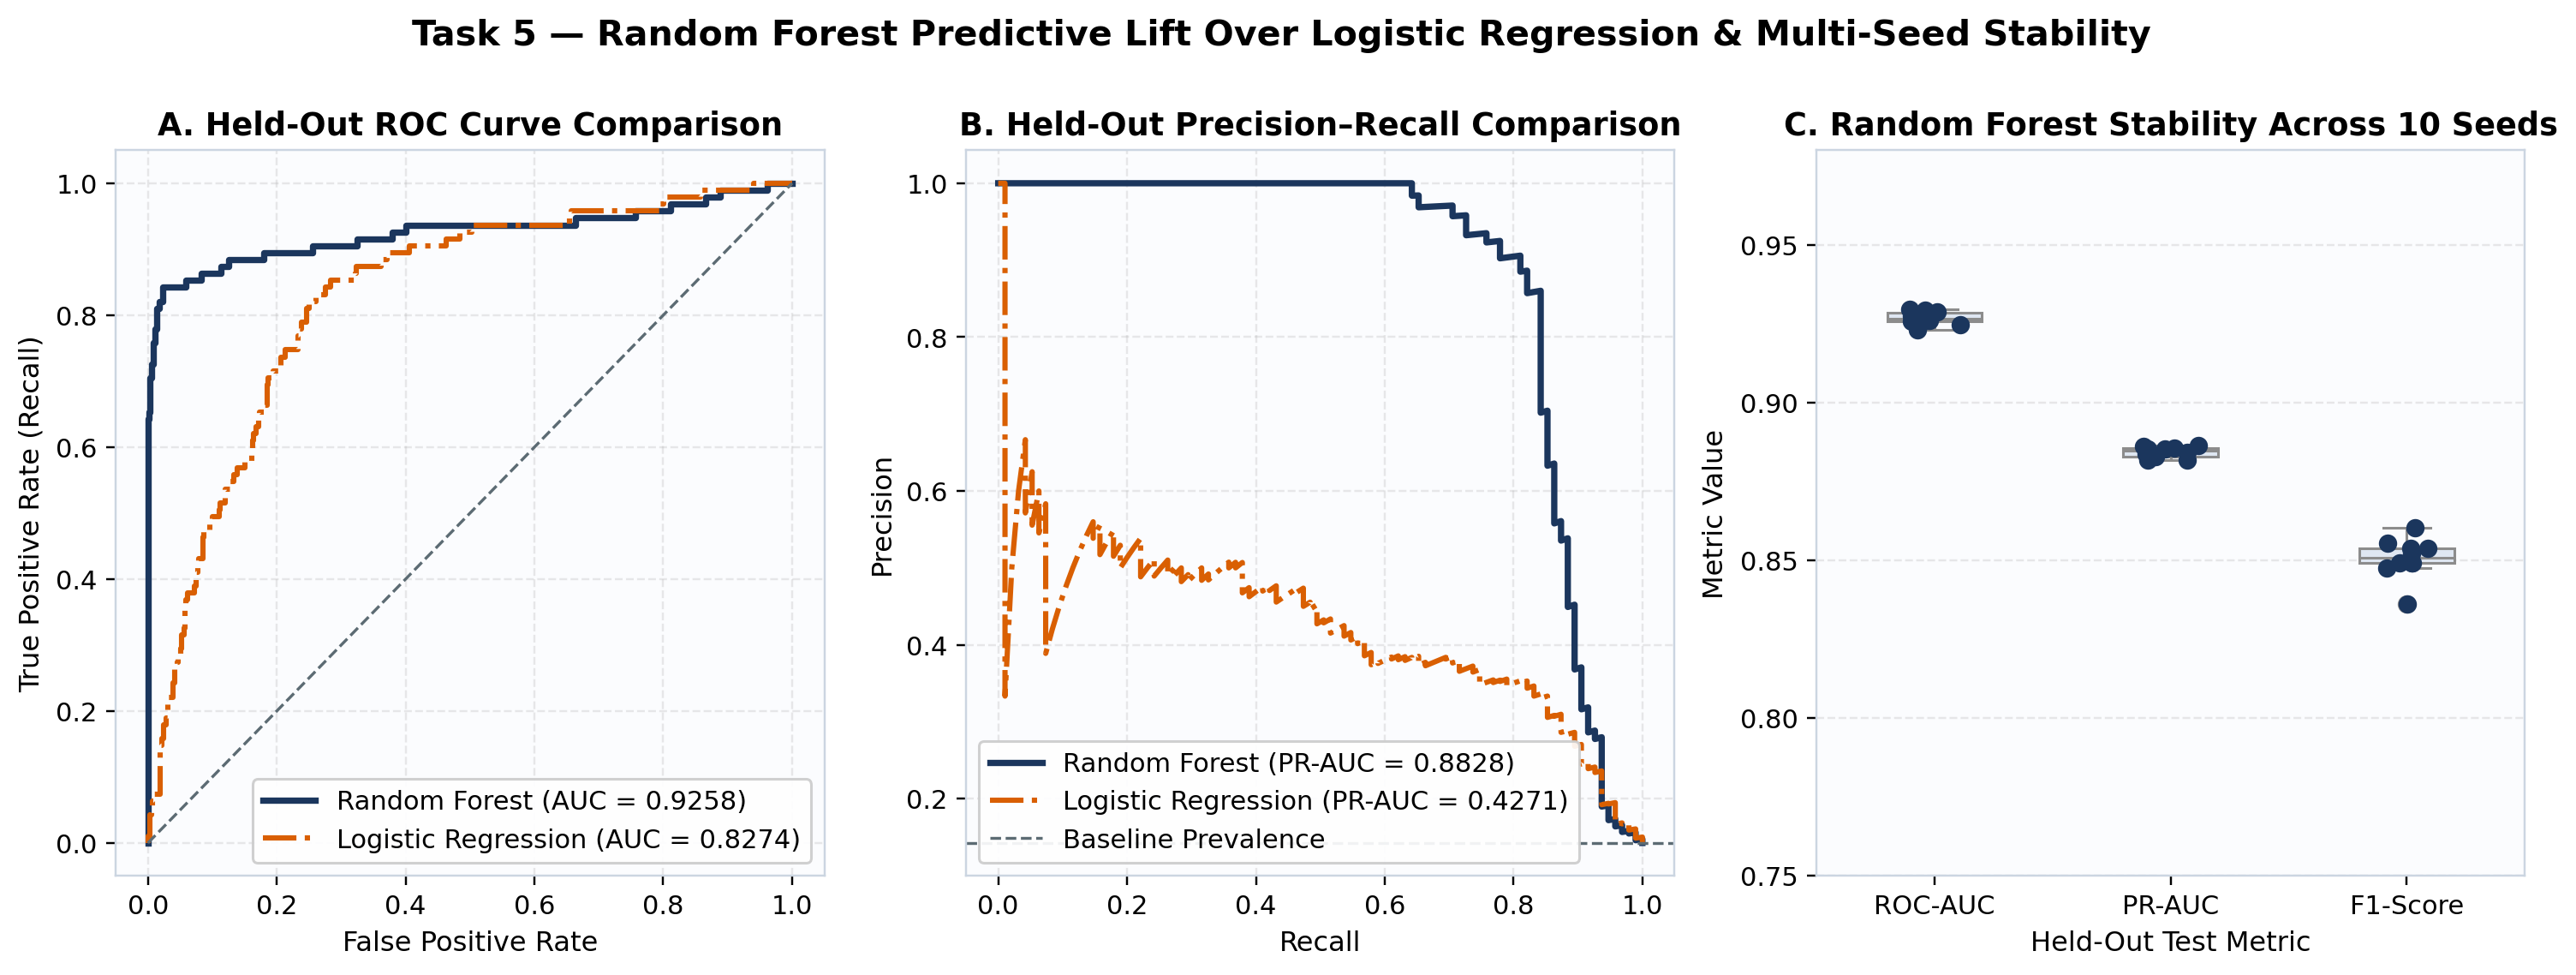

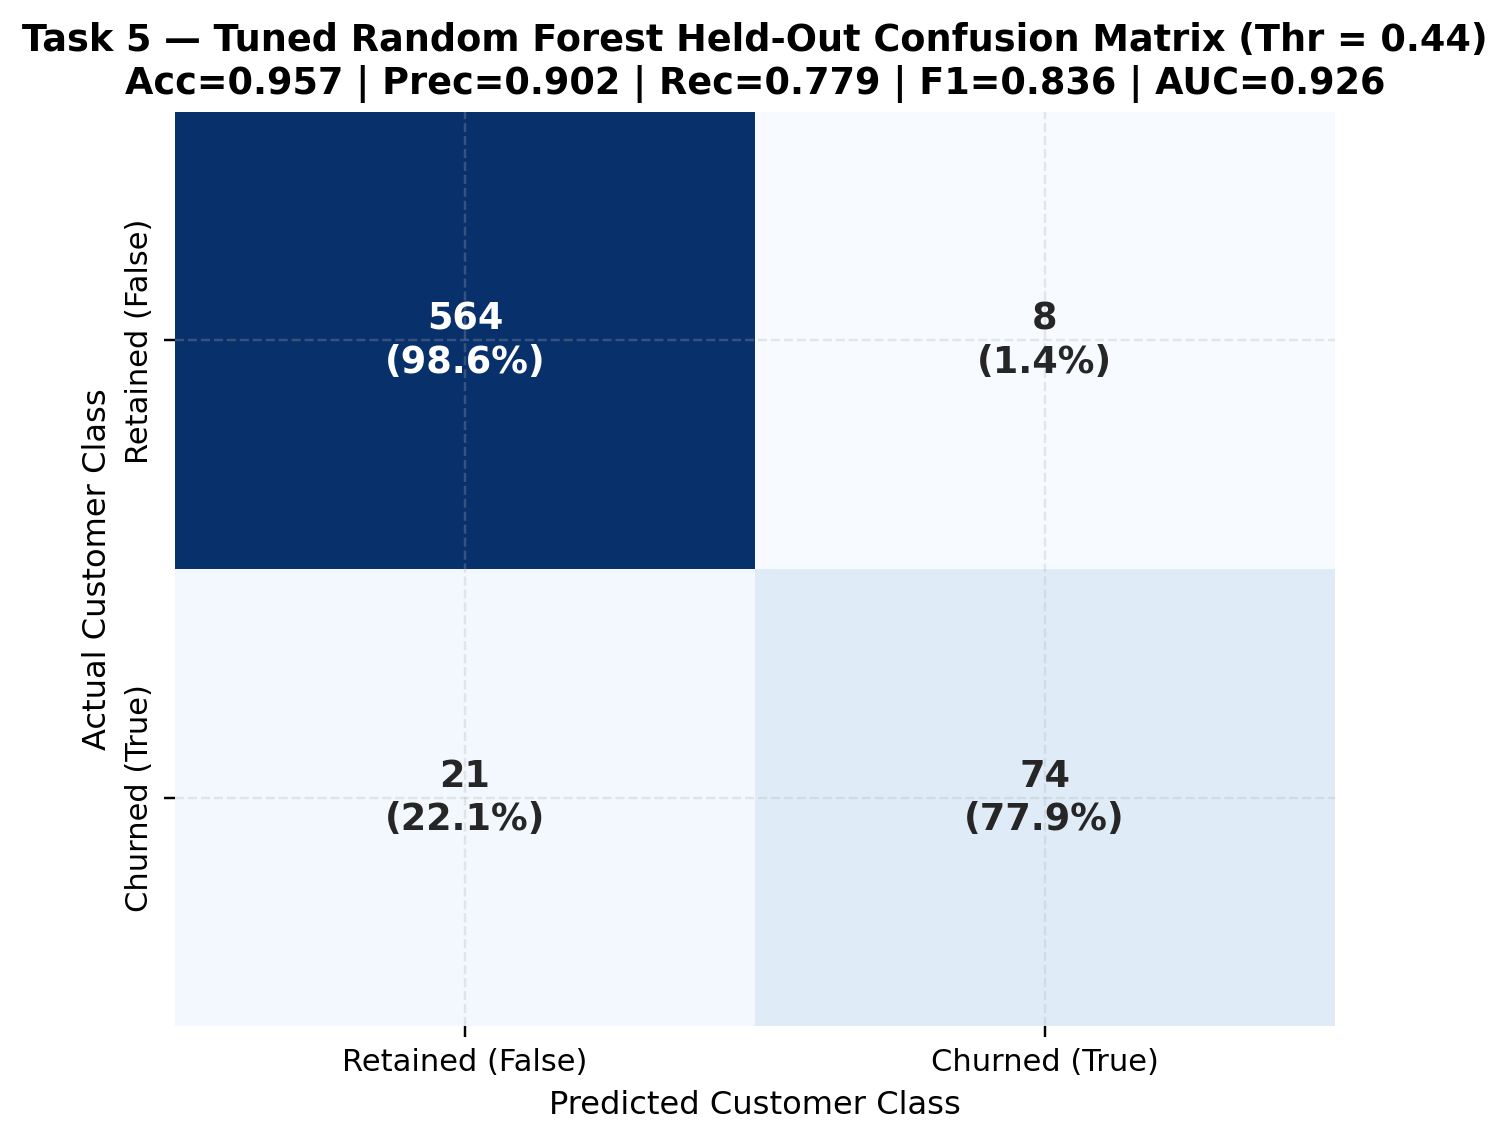

In [2]:
display(Image(filename=str(ROOT / 'results/figures/fig11_rf_feature_importance_mdi_vs_permutation.png')))
display(Image(filename=str(ROOT / 'results/figures/fig12_rf_roc_pr_and_seed_stability.png')))
display(Image(filename=str(ROOT / 'results/figures/fig13_rf_confusion_matrix.png')))